# Hazard models and clustering

In this notebook, we build the models set out in `03-HazardResearch.md`. Everything is chosen on the training customers,
the validation set is used as a single check, and the test set is only used once, at the end. The complete workings
are in `Alex/modelling/`.

The first step is to run `01-Data.ipynb`, as it loads the shared split this notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from lifelines import CoxTimeVaryingFitter
from scipy.stats import bootstrap
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
Y = "default payment next month"
SEED = 2026
wide = {part: pd.read_csv(ROOT / "data" / "processed" / f"taiwan-{part}.csv", index_col="ID")
        for part in ("train", "validation")}
{part: df.shape for part, df in wide.items()}

{'train': (17997, 24), 'validation': (5999, 24)}

## 1. The person-month table

A hazard model is fitted on one row per customer for each month that they are at risk. Months are numbered
from April ($t = 1$) to October ($t = 7$), and model June to October, as the payment ratio needs the previous month's
bill. In June to September the event considered is being 2 or more months behind, and in October it is the real default label.
2 is a cut-off rather than the most a customer can be behind, as the status codes go up to 8 (eight months late).
In the training data 12% of customer-months are 2 or more behind but under 2% are 3 or more. Because of this, we group
everything from 2 upwards as, for example, we would have very few data points for 4+ months late. Being 2+ behind is not a default, it is a stand-in so that the earlier months have an
event.
We treat everyone to be at risk every month of their loan. We gather the covariates come from the month before. This makes sure that a month's own status never
predicts itself. This gives each customer five rows. The October row is the row that we score on.


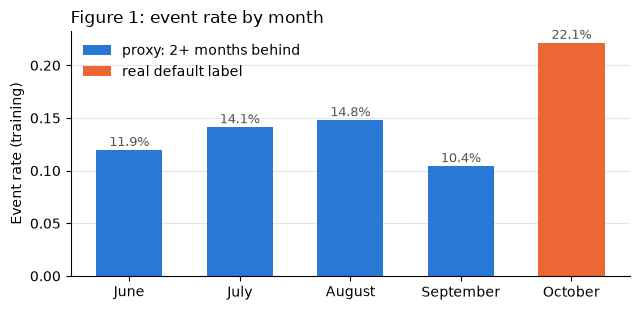

In [2]:
STATUS_CODES, FIRST_T, OCTOBER = [-2, -1, 0, 1, 2, 3], 3, 7
CATEGORIES = {"status_lag": (STATUS_CODES, -1), "SEX": ([1, 2], 1), "EDUCATION": ([1, 2, 3, 4], 1),
              "MARRIAGE": ([1, 2, 3], 1), "t": (list(range(FIRST_T, OCTOBER + 1)), FIRST_T)}
CONTINUOUS = ["util_lag", "payratio_lag", "log_limit", "age"]


def long_table(df):
    """One row per customer -> one row per customer per month, June (t = 3) to October (t = 7)."""
    pieces = []
    for t in range(FIRST_T, OCTOBER + 1):
        now, lag = 7 - t, 8 - t                   # raw columns run backwards: PAY_1 is September
        out = pd.DataFrame({"t": t}, index=df.index)
        out["event"] = df[Y] if t == OCTOBER else (df[f"PAY_{now}"] >= 2).astype(int)
        out["status_lag"] = df[f"PAY_{lag}"].clip(upper=3)
        out["util_lag"] = (df[f"BILL_AMT{lag}"] / df["LIMIT_BAL"]).clip(upper=1.5)
        bill_before = df[f"BILL_AMT{lag + 1}"]                       # PAY_AMTk pays the previous month's bill
        out["payratio_lag"] = (df[f"PAY_AMT{lag}"] / bill_before).where(bill_before > 0, 1).clip(0, 1)
        out["log_limit"], out["age"] = np.log(df["LIMIT_BAL"]), df["AGE"]
        out[["SEX", "EDUCATION", "MARRIAGE"]] = df[["SEX", "EDUCATION", "MARRIAGE"]]
        pieces.append(out)
    return pd.concat(pieces).sort_index(kind="stable")


long = {part: long_table(df) for part, df in wide.items()}
mean, sd = long["train"][CONTINUOUS].mean(), long["train"][CONTINUOUS].std()     # training rows only


def design(df):
    """Categories as 0/1 columns (dropping a reference code), continuous columns standardised."""
    X = pd.DataFrame({"t": df["t"], "event": df["event"]}, index=df.index)
    X[CONTINUOUS] = (df[CONTINUOUS] - mean) / sd
    for col, (codes, ref) in CATEGORIES.items():
        for code in codes:
            if code != ref:
                X[f"{col}_{code}"] = (df[col] == code).astype(float)
    return X


train, val = design(long["train"]), design(long["validation"])
FEATURES = [c for c in train.columns if c not in ("t", "event")]
NO_MONTHS = [c for c in FEATURES if not c.startswith("t_")]
october = lambda df: df[df["t"] == OCTOBER]
assert (october(train)["event"] == wide["train"][Y]).all()

rates = long["train"].groupby("t")["event"].mean()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(["June", "July", "August", "September"], rates.iloc[:-1], width=0.6, color="#2a78d6",
       label="proxy: 2+ months behind")
ax.bar(["October"], rates.iloc[-1:], width=0.6, color="#eb6834", label="real default label")
for x, r in enumerate(rates):
    ax.annotate(f"{r:.1%}", (x, r), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9,
                color="#555555")
ax.set_ylabel("Event rate (training)")
ax.set_title("Figure 1: event rate by month", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

From our data, only October is a real default, so the earlier months answer a slightly different question, does the customer
fall 2+ months behind?. We use 2+ months behind as a proxy for default in this hazard model as a hazard model needs to have a probability of default for each month.
This is a big drawback for our data when building a hazard model, ideally we would us the industry standard of 90 days past due (3+ months) but we don't have enough data
to make this a reasonable option.

## 2. The models

Every model predicts the monthly hazard from last month's covariates, with a separate intercept $\alpha_t$ for
each month:

$$\text{link}\big(h(t \mid x)\big) = \alpha_t + \beta^\top x_{t-1}$$

The logit model uses $\log\frac{h}{1-h}$ and the cloglog model uses $\log(-\log(1-h))$. The penalised models add an
L1 or L2 penalty, with the strength C = 0.01 chosen by cross-validation on log loss in `Alex/modelling/`. The Cox
model is $h(t \mid x) = h_0(t)\,e^{\beta^\top x_{t-1}}$, where the baseline $h_0$ takes the place of the month
intercepts. This can all be fitted as ordinary regression because the probability of a customer's history is the
product, over their months, of $h$ (event) or $1-h$ (no event), which is a Bernoulli likelihood over the rows
(Allison, 1982).

We also fit a logistic regression on the October rows only, with one row per customer, as the fair test of whether
the extra months help.

In [3]:
def fit_glm(data, link=sm.families.links.Logit(), cols=FEATURES):
    """Discrete-time hazard as a binomial GLM, with standard errors clustered by customer."""
    model = sm.GLM(data["event"], sm.add_constant(data[cols]), family=sm.families.Binomial(link=link))
    return model.fit(cov_type="cluster", cov_kwds={"groups": data.index.to_numpy()})


def fit_penalised(data, l1_ratio, C=0.01):
    model = LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear" if l1_ratio else "lbfgs", max_iter=2000)
    return model.fit(data[FEATURES], data["event"])


def fit_cox(data):
    """Cox with time-varying covariates; each row is the interval (t-1, t]. A small ridge penalty and a shorter
    Newton step keep it from diverging, as the status columns are nearly separable in some months."""
    df = data[NO_MONTHS].assign(id=data.index, start=data["t"] - 1, stop=data["t"],
                                event=data["event"].astype(bool)).reset_index(drop=True)
    return CoxTimeVaryingFitter(penalizer=0.01).fit(df, id_col="id", event_col="event", start_col="start",
                                                    stop_col="stop", fit_options={"step_size": 0.3}, show_progress=False)


def predict(model, rows):
    """The hazard for each row. Cox has no predict for time-varying fits, so its monthly hazard is built from the
    baseline: h = 1 - exp(-[H0(t) - H0(t-1)] * exp((x - mean)'beta))."""
    if isinstance(model, CoxTimeVaryingFitter):
        H0 = model.baseline_cumulative_hazard_.iloc[:, 0]
        h0 = H0.reindex(rows["t"]).to_numpy() - H0.reindex(rows["t"] - 1).fillna(0).to_numpy()
        p = 1 - np.exp(-h0 * model.predict_partial_hazard(rows[model.params_.index]).to_numpy())
    elif isinstance(model, LogisticRegression):
        p = model.predict_proba(rows[model.feature_names_in_])[:, 1]
    else:
        p = model.predict(sm.add_constant(rows[[c for c in model.model.exog_names if c != "const"]],
                                          has_constant="add"))
    return pd.Series(np.asarray(p), index=rows.index)


def score(y, p):
    return {"AUC": roc_auc_score(y, p), "avg precision": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}


MODELS = {
    "logit hazard": fit_glm,
    "cloglog hazard": lambda d: fit_glm(d, sm.families.links.CLogLog()),
    "logit hazard, L1": lambda d: fit_penalised(d, l1_ratio=1.0),
    "logit hazard, L2": lambda d: fit_penalised(d, l1_ratio=0.0),
    "Cox, time-varying": fit_cox,
    "logistic, October rows only": lambda d: fit_glm(october(d), cols=NO_MONTHS),
}

## 3. Comparing the models

A customer's rows are not independent, so we cross-validate with whole customers left out: `GroupKFold` keeps all
five of a customer's rows in the same fold. Each fold is scored on its left-out customers' October rows, which is
the number the group compares.

In [4]:
FOLDS = list(GroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(train, groups=train.index))
cv = {}
for name, fit in MODELS.items():
    folds = []
    for fit_idx, score_idx in FOLDS:
        held_out = october(train.iloc[score_idx])
        folds.append(score(held_out["event"], predict(fit(train.iloc[fit_idx]), held_out)))
    cv[name] = pd.DataFrame(folds)
cv_table = pd.DataFrame({name: f.mean() for name, f in cv.items()}).T
cv_table["AUC sd"] = [f["AUC"].std() for f in cv.values()]
cv_table.round(4)

,AUC,avg precision,Brier,log loss,AUC sd
logit hazard,0.7330,0.5066,0.1424,0.4582,0.0125
cloglog hazard,0.7303,0.5063,0.1436,0.4652,0.0121
"logit hazard, L1",0.7298,0.5014,0.1420,0.4560,0.0134
"logit hazard, L2",0.7324,0.5027,0.1418,0.4553,0.0129
"Cox, time-varying",0.7309,0.5049,0.1450,0.4722,0.0124
"logistic, October rows only",0.7469,0.5161,0.1394,0.4456,0.0105


A bigger model always fits the training data better, so AIC and BIC charge for the extra parameters. Here we add
the covariates to the logit hazard in steps. BIC needs a sample size, and it is not clear whether this should be
the 90,000 rows or the 18,000 customers, so both are shown.

In [5]:
steps = {"months only": [c for c in FEATURES if c.startswith("t_")],
         "+ last month's status": [c for c in FEATURES if c.startswith(("t_", "status"))],
         "+ utilisation, payment ratio": [c for c in FEATURES if c.startswith(("t_", "status", "util", "payratio"))],
         "+ limit, age, demographics": FEATURES}
rows = []
for name, cols in steps.items():
    res, k = fit_glm(train, cols=cols), len(cols) + 1
    rows.append({"model": name, "parameters": k, "log-likelihood": res.llf, "AIC": res.aic,
                 "BIC (rows)": -2 * res.llf + k * np.log(len(train)),
                 "BIC (customers)": -2 * res.llf + k * np.log(train.index.nunique())})
pd.DataFrame(rows).set_index("model").round(1)

,parameters,log-likelihood,AIC,BIC (rows),BIC (customers)
model,,,,,
months only,5,-36962.4,73934.9,73981.9,73973.9
+ last month's status,10,-26443.9,52907.8,53001.9,52985.8
"+ utilisation, payment ratio",12,-26107.4,52238.9,52351.8,52332.5
"+ limit, age, demographics",20,-25783.9,51607.8,51795.9,51763.8


## 4. The check on the validation customers

Each model is now fitted once on all the training customers and scored on the validation customers, who have not
been used for anything so far.

In [6]:
fitted = {name: fit(train) for name, fit in MODELS.items()}
y_val = october(val)["event"]
p_val = {name: predict(m, october(val)) for name, m in fitted.items()}
pd.DataFrame({name: score(y_val, p) for name, p in p_val.items()}).T.round(4)

,AUC,avg precision,Brier,log loss
logit hazard,0.7438,0.5297,0.1380,0.4460
cloglog hazard,0.7442,0.5323,0.1385,0.4502
"logit hazard, L1",0.7368,0.5212,0.1382,0.4460
"logit hazard, L2",0.7394,0.5236,0.1380,0.4457
"Cox, time-varying",0.7447,0.5307,0.1407,0.4597
"logistic, October rows only",0.7503,0.5360,0.1365,0.4389


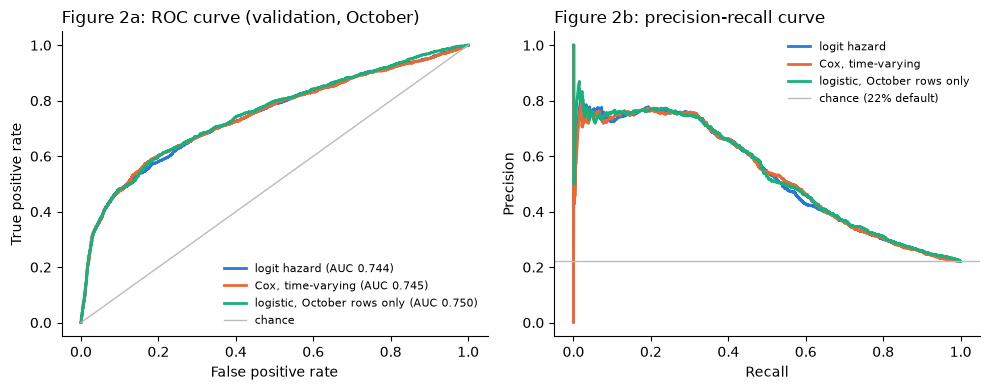

In [7]:
SHOW = {"logit hazard": "#2a78d6", "Cox, time-varying": "#eb6834", "logistic, October rows only": "#1baf7a"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, colour in SHOW.items():
    fpr, tpr, _ = roc_curve(y_val, p_val[name])
    precision, recall, _ = precision_recall_curve(y_val, p_val[name])
    ax1.plot(fpr, tpr, linewidth=2, color=colour, label=f"{name} (AUC {roc_auc_score(y_val, p_val[name]):.3f})")
    ax2.plot(recall, precision, linewidth=2, color=colour, label=name)
ax1.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="chance")
ax2.axhline(y_val.mean(), color="#bbbbbb", linewidth=1, label=f"chance ({y_val.mean():.0%} default)")
ax1.set(xlabel="False positive rate", ylabel="True positive rate")
ax2.set(xlabel="Recall", ylabel="Precision")
ax1.set_title("Figure 2a: ROC curve (validation, October)", loc="left")
ax2.set_title("Figure 2b: precision-recall curve", loc="left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

The hazard models lie almost on top of each other, so only three are drawn. To check whether the October-only
model is really better than the logit hazard, we use a paired bootstrap over the validation customers, keeping each
customer's label and both predictions together.

In [8]:
def auc_difference(y, p_a, p_b):
    return roc_auc_score(y, p_a) - roc_auc_score(y, p_b)


a, b = "logistic, October rows only", "logit hazard"
boot = bootstrap((y_val.to_numpy(), p_val[a].to_numpy(), p_val[b].to_numpy()), auc_difference, paired=True,
                 vectorized=False, n_resamples=1000, method="percentile", random_state=SEED)
print(f"AUC difference {auc_difference(y_val, p_val[a], p_val[b]):.4f}, 95% interval "
      f"[{boot.confidence_interval.low:.4f}, {boot.confidence_interval.high:.4f}]")

AUC difference 0.0065, 95% interval [-0.0021, 0.0147]


## 5. Calibration

A good Brier score does not guarantee good calibration, so we check it directly for the logit hazard - by month,
comparing the average predicted hazard with the actual event rate, and in October, using ten equal-sized bins.

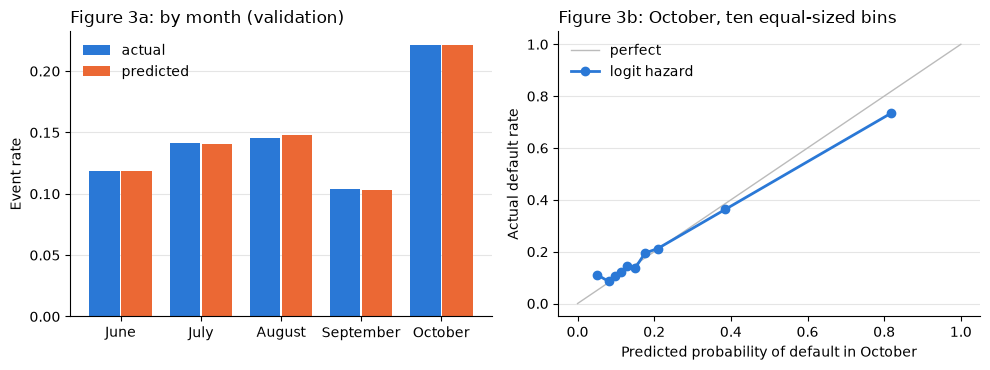

In [9]:
logit = fitted["logit hazard"]
term = pd.DataFrame({"actual": val.groupby("t")["event"].mean(),
                     "predicted": predict(logit, val).groupby(val["t"]).mean()})
actual_rate, predicted_rate = calibration_curve(y_val, p_val["logit hazard"], n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(term))
ax1.bar(x - 0.2, term["actual"], width=0.38, color="#2a78d6", label="actual")
ax1.bar(x + 0.2, term["predicted"], width=0.38, color="#eb6834", label="predicted")
ax1.set_xticks(x, ["June", "July", "August", "September", "October"])
ax1.set_ylabel("Event rate")
ax1.set_title("Figure 3a: by month (validation)", loc="left")
ax1.legend(frameon=False)
ax2.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="perfect")
ax2.plot(predicted_rate, actual_rate, marker="o", markersize=6, linewidth=2, color="#2a78d6", label="logit hazard")
ax2.set(xlabel="Predicted probability of default in October", ylabel="Actual default rate")
ax2.set_title("Figure 3b: October, ten equal-sized bins", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 6. Predicting the next month

To test whether the model generalises forward in time, we fit on the training customers' months up to August and
predict September for the validation customers, and compare this with a model that has seen September. Both leave
out the month intercepts, as the model fitted up to August has no September intercept, so we only compare AUC -
a missing intercept shifts every prediction in the month equally, which does not change the ranking.

In [10]:
SEPTEMBER = OCTOBER - 1
val_sep = val[val["t"] == SEPTEMBER]
pd.Series({label: roc_auc_score(val_sep["event"], predict(fit_glm(train[train["t"] <= last], cols=NO_MONTHS), val_sep))
           for label, last in (("fitted up to August", SEPTEMBER - 1), ("fitted up to September", SEPTEMBER))},
          name="AUC, September").round(4)

fitted up to August       0.8568
fitted up to September    0.8584
Name: AUC, September, dtype: float64

## 7. Clustering: customer types

We now group the customers by their April-September behaviour, using k-means on mean utilisation, change in
utilisation, months behind, worst status, months inactive, mean payment ratio, log limit and age. Each feature is
standardised, as k-means uses distances. The clusters are built from the training customers only and the October
label is not used to build them. K = 5 gives clusters that are easy to describe; section 9 checks whether the
choice of K matters.

In [11]:
def customer_features(df):
    status = df[[f"PAY_{k}" for k in range(1, 7)]]
    util = pd.DataFrame({k: (df[f"BILL_AMT{k}"] / df["LIMIT_BAL"]).clip(-0.5, 1.5) for k in range(1, 7)})
    paid = pd.DataFrame({k: (df[f"PAY_AMT{k}"] / df[f"BILL_AMT{k + 1}"]).where(df[f"BILL_AMT{k + 1}"] > 0, 1)
                            .clip(0, 1) for k in range(1, 6)})
    return pd.DataFrame({"mean utilisation": util.mean(axis=1), "utilisation change": util[1] - util[6],
                         "months behind": (status >= 1).sum(axis=1), "worst status": status.clip(lower=0).max(axis=1),
                         "months inactive": (status == -2).sum(axis=1), "mean payment ratio": paid.mean(axis=1),
                         "log limit": np.log(df["LIMIT_BAL"]), "age": df["AGE"]}, index=df.index)


feats = {part: customer_features(df) for part, df in wide.items()}
scaler = StandardScaler().fit(feats["train"])
Z = {part: scaler.transform(f) for part, f in feats.items()}
kmeans = lambda k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z["train"])

K = 5
km = kmeans(K)
cluster_train = pd.Series(km.labels_, index=feats["train"].index)
cluster_val = pd.Series(km.predict(Z["validation"]), index=feats["validation"].index).loc[y_val.index]
profile = feats["train"].groupby(cluster_train).mean()
profile["customers"] = cluster_train.value_counts().sort_index()
profile["default rate"] = wide["train"][Y].groupby(cluster_train).mean()
profile.round(2)

,mean utilisation,utilisation change,months behind,worst status,months inactive,mean payment ratio,log limit,age,customers,default rate
0,0.05,-0.00,0.31,0.41,0.33,0.79,12.14,36.01,4571,0.15
1,0.56,0.05,0.04,0.07,0.01,0.09,11.77,34.88,4967,0.11
2,0.02,0.02,0.29,0.29,5.07,0.98,12.14,36.71,2419,0.18
3,0.60,-0.00,3.33,2.35,0.03,0.10,11.03,34.69,3607,0.51
4,0.59,0.66,0.32,0.42,0.32,0.24,11.04,35.79,2433,0.20


The clusters are easy to describe: customers who use little of their limit and pay it off (cluster 0), customers
carrying a balance and paying little each month (1), inactive accounts (2), customers who are often behind, with a
51% default rate (3), and customers whose balance is growing (4).

## 8. The metric within each cluster, and leaving a cluster out

First, the logit hazard's AUC on the validation customers in each cluster, with a 95% bootstrap interval over
customers. Second, we refit the logit hazard without one cluster's training customers and score that cluster's
validation customers, a type of customer the model has never seen.

In [12]:
def bootstrap_auc(y, p):
    ci = bootstrap((y.to_numpy(), p.to_numpy()), roc_auc_score, paired=True, vectorized=False,
                   n_resamples=500, method="percentile", random_state=SEED).confidence_interval
    return ci.low, ci.high


def by_cluster(cl_train, cl_val, k):
    """AUC in each cluster with the cluster in training, and with it left out."""
    p_full = p_val["logit hazard"]
    rows = []
    for c in range(k):
        in_c = (cl_val == c).to_numpy()
        without_c = fit_glm(train[(cl_train.loc[train.index] != c).to_numpy()])
        rows.append({"cluster": c, "customers": int(in_c.sum()), "default rate": y_val[in_c].mean(),
                     "AUC": roc_auc_score(y_val[in_c], p_full[in_c]),
                     "AUC, cluster left out": roc_auc_score(y_val[in_c], predict(without_c, october(val))[in_c])})
    out = pd.DataFrame(rows).set_index("cluster")
    out["change"] = out["AUC, cluster left out"] - out["AUC"]
    return out


within = by_cluster(cluster_train, cluster_val, K)
within[["95% low", "95% high"]] = [bootstrap_auc(y_val[(cluster_val == c).to_numpy()],
                                                 p_val["logit hazard"][(cluster_val == c).to_numpy()])
                                   for c in range(K)]
print("overall validation AUC:", round(roc_auc_score(y_val, p_val["logit hazard"]), 3))
within.round(3)

overall validation AUC: 0.744


,customers,default rate,AUC,"AUC, cluster left out",change,95% low,95% high
cluster,,,,,,,
0,1602,0.143,0.653,0.658,0.005,0.616,0.691
1,1646,0.113,0.636,0.620,-0.016,0.592,0.677
2,762,0.196,0.638,0.630,-0.008,0.585,0.688
3,1199,0.510,0.745,0.736,-0.008,0.720,0.771
4,790,0.192,0.660,0.660,-0.001,0.609,0.714


## 9. Does the number of clusters matter?

The clusters are a tool rather than true groups, so we repeat section 8 for K = 2 to 8. If the weakest cluster's
AUC and the largest drop from leaving a cluster out barely change with K, the choice of K does not matter for our
conclusions.

In [13]:
rows = []
for k in range(2, 9):
    km_k = kmeans(k)
    res = by_cluster(pd.Series(km_k.labels_, index=feats["train"].index),
                     pd.Series(km_k.predict(Z["validation"]), index=feats["validation"].index).loc[y_val.index], k)
    rows.append({"K": k, "lowest AUC in a cluster": res["AUC"].min(), "highest AUC in a cluster": res["AUC"].max(),
                 "largest drop when left out": res["change"].min()})
pd.DataFrame(rows).set_index("K").round(3)

,lowest AUC in a cluster,highest AUC in a cluster,largest drop when left out
K,,,
2,0.634,0.780,-0.051
3,0.623,0.745,-0.015
4,0.616,0.744,-0.008
5,0.636,0.745,-0.016
6,0.614,0.727,-0.015
7,0.621,0.698,-0.059
8,0.622,0.705,-0.060


## 10. Conclusion

All of the hazard models perform similarly. In cross-validation the AUC only ranges from 0.730 to 0.733, so
changing the link, adding a penalty or moving to continuous time doesn't have a massive effect and is not what limits the model. Adding covariates
does help. AIC and BIC both choose the full model whatever the sample size. As the simplest version does
as well as any other, the logit hazard is the model we take forward. This was to be expected from earlier research and prior experience.

The main finding is that using the earlier months does not help with predicting October. The logistic regression
on the October rows alone does better in cross-validation (AUC 0.747 against 0.733), although on the validation
customers the gap is only 0.0065 and the bootstrap interval includes 0, so we cannot say it is a real difference.
We think this is because June to September use the proxy event, so the coefficients shared across the months are
answering two slightly different questions. Where the hazard model does add value is over time. It matches the
event rate in every month almost exactly, it can give a probability for any month rather than just October, and a
model fitted up to August predicts September almost as well as one that has seen September (AUC 0.857 against
0.858). It is less good at the extremes in October, where it is too confident at both ends, so calibrating the
probabilities on the validation set, as we did in Sprint 0, would be worth doing before the final predictions.

The clustering shows how much a single AUC can hide. Overall the model's AUC is 0.74, but within four of the five
clusters it is only 0.64 to 0.66, and it only reaches 0.75 in the high-risk cluster. So a large part of the overall
AUC comes from telling types of customer apart, rather than ranking customers within a type, and this is true for
every number of clusters we tried. Leaving a type of customer out of training costs little for a moderate number of
clusters (at most 0.016), but up to 0.06 when the group left out is very large or very specific, so how well the
model generalises to new types of customer depends on how different they are.

For the group, this means a single AUC on the shared test set is not enough to call one model truly best. The
differences between our hazard models (around 0.01) are no bigger than the variation between folds, and the overall
AUC flatters every model for most customers. Reporting the AUC within each cluster, and with clusters left out, for
Oscar's and Louis's models too, would give a much fairer comparison.

The main limitations are that the event before October is a proxy, the data only covers one six-month window with
no account age, and the clusters are a convenient way of splitting the data rather than natural groups. The next
steps are to calibrate the logit hazard, write its predictions for the test set, and run the cluster checks on the
other models.